# Results and domain shift

Tables and figures of the evaluation: 9 runs (3 models, input size S = 320/640/960) on `valid`, `test` and the self-collected `phone` set. Reads files only, no GPU needed.

- Input: `results/summary/*.csv`, written by `python -m iiss.analysis.domain_shift` and checked here against `results/eval/`. A stale table raises an error.
- Values are mask AP x 100 (pycocotools, `last` checkpoint).
- The sets have GT for different classes, so the comparison between sets uses the *common classes* (GT in all three sets). This does not remove every difference: label habits and instance counts per class differ too.
- A run marked `*` hit the 2-hour training cap and is undertrained (`m2f_s960_seed42`; tables indexed by run id carry no mark).
- The phone set is small (2 to 47 instances per class), so small differences between runs are not meaningful. There is one seed per run.
- `SMOKE = True` draws the figures without saving them.

## Parameters

In [1]:
SUMMARY_DIR = 'results/summary'
EVAL_ROOT = 'results/eval'
SMOKE = False         # True: do not write the figures
SAVE = None if SMOKE else True

In [2]:
import pandas as pd

from iiss.analysis import result_plots as rp
from iiss.analysis.domain_shift import load_tables
from iiss.utils.paths import resolve_path

pd.set_option('display.max_columns', 30, 'display.max_rows', 100, 'display.width', 200)
pd.set_option('display.float_format', '{:.1f}'.format)
tables = load_tables(SUMMARY_DIR, EVAL_ROOT)
main, common = tables['main_results'], tables['common_classes']
out = resolve_path(SUMMARY_DIR)
print(len(main), 'rows;', len(common), 'common classes:', ', '.join(common))

27 rows; 17 common classes: backpack, bed, book, bottle, bowl, ceiling-merged, chair, door-stuff, floor-other-merged, food-other-merged, light, pillow, plate, spoon, table-merged, towel, wall-other-merged


## Evaluation sets

In [3]:
main.drop_duplicates('eval_set')[
    ['eval_set', 'n_images', 'n_gt', 'n_classes', 'n_common_classes']]

,eval_set,n_images,n_gt,n_classes,n_common_classes
0,valid,166,2022,58,17
1,test,359,5344,69,17
2,phone,40,166,17,17


## AP against input size (common classes)

All three panels average over the same classes.

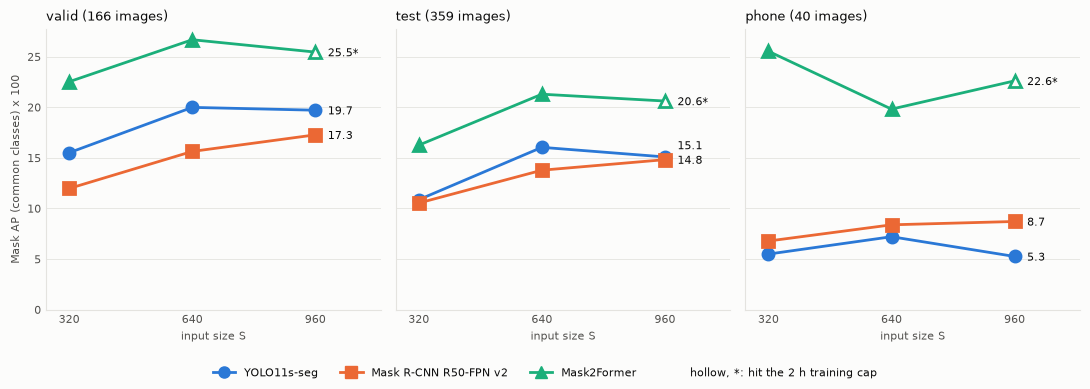

In [4]:
rp.plot_ap_vs_size(main, 'AP_common', SAVE and out / 'ap_vs_size_common.png');

In [5]:
rp.wide_table(main, 'AP_common')

,valid,test,phone
YOLO11s-seg 320,15.5,10.9,5.5
YOLO11s-seg 640,20.0,16.0,7.2
YOLO11s-seg 960,19.7,15.1,5.3
Mask R-CNN R50-FPN v2 320,12.0,10.5,6.8
Mask R-CNN R50-FPN v2 640,15.6,13.8,8.4
Mask R-CNN R50-FPN v2 960,17.3,14.8,8.7
Mask2Former 320,22.5,16.3,25.5
Mask2Former 640,26.7,21.3,19.8
Mask2Former 960*,25.5,20.6,22.6


## AP against input size (all classes with GT)

Each panel averages over a different class list: compare models and sizes inside a panel, not the panels with each other.

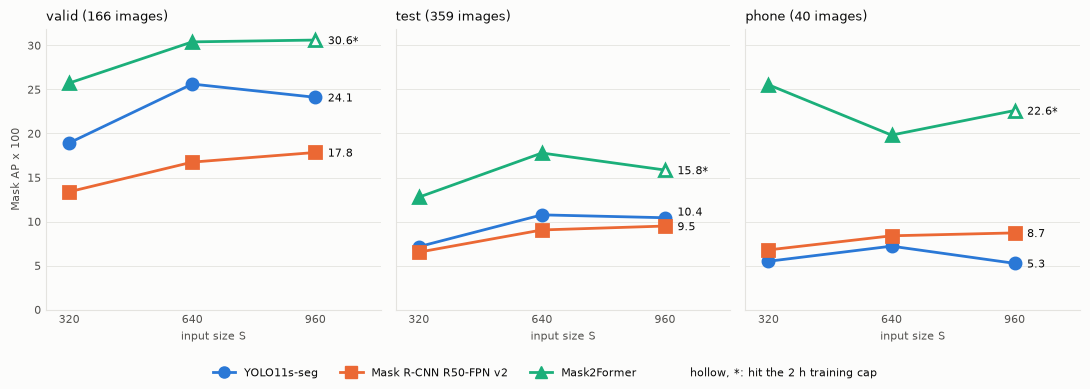

In [6]:
rp.plot_ap_vs_size(main, 'AP', SAVE and out / 'ap_vs_size_all.png');

In [7]:
pd.concat({m: rp.wide_table(main, m) for m in ('AP', 'AP50', 'AP75', 'bbox_AP')}, axis=1)

AP             AP50             AP75            bbox_AP           
                          valid test phone valid test phone valid test phone   valid test phone
YOLO11s-seg 320            18.9  7.1   5.5  28.3 12.4   9.0  20.7  7.2   6.2    21.8  8.8   7.1
YOLO11s-seg 640            25.6 10.8   7.2  35.6 16.7   9.4  26.3 11.4   7.9    28.4 12.4   7.1
YOLO11s-seg 960            24.1 10.4   5.3  32.7 16.1   7.6  25.4 11.0   5.8    26.3 12.1   7.0
Mask R-CNN R50-FPN v2 320  13.4  6.5   6.8  21.1 11.3  11.4  13.9  6.7   7.0    14.8  7.7   8.3
Mask R-CNN R50-FPN v2 640  16.7  9.0   8.4  25.9 14.9  14.5  17.7  9.1   7.5    18.6 10.2  11.6
Mask R-CNN R50-FPN v2 960  17.8  9.5   8.7  25.8 15.4  13.9  19.0  9.8  10.0    19.0 10.8  11.8
Mask2Former 320            25.7 12.8  25.5  35.9 19.8  32.2  25.4 12.5  25.6    25.5 13.6  25.7
Mask2Former 640            30.4 17.8  19.8  40.3 24.9  27.8  30.7 18.3  19.3    30.4 17.8  20.4
Mask2Former 960*           30.6 15.8  22.6  40.8 22.5  27.7  32.9 16.9  22.7    30.8 15.8  22.9

## Domain shift: valid, test, phone (common classes)

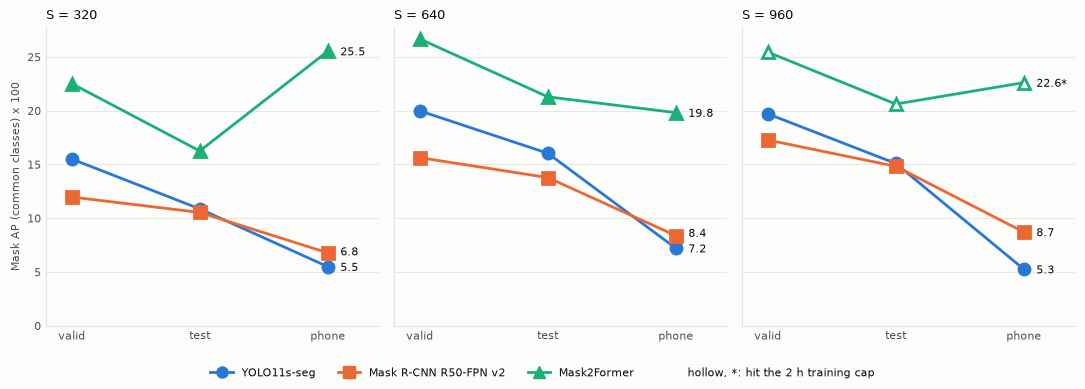

In [8]:
rp.plot_domain_shift(main, 'AP_common', SAVE and out / 'domain_shift_common.png');

`delta` is the change in AP points, `relative` the change in percent of the earlier set.

In [9]:
shift = tables['domain_shift'].query("metric == 'AP_common'").copy()
shift['step'] = shift['from'] + ' to ' + shift['to']
shift[['delta', 'relative']] *= 100
wide = shift.pivot(index='run_id', columns='step', values=['delta', 'relative'])
wide.loc[main['run_id'].unique()].reindex(columns=shift['step'].unique(), level=1)

delta                                   relative                             
step                 valid to test test to phone valid to phone valid to test test to phone valid to phone
run_id                                                                                                    
yolo_s320_seed42              -4.6          -5.4          -10.0         -29.9         -49.5          -64.6
yolo_s640_seed42              -3.9          -8.8          -12.8         -19.8         -55.1          -64.0
yolo_s960_seed42              -4.6          -9.8          -14.5         -23.4         -65.2          -73.3
maskrcnn_s320_seed42          -1.4          -3.8           -5.2         -12.0         -35.6          -43.4
maskrcnn_s640_seed42          -1.9          -5.4           -7.3         -11.9         -39.2          -46.4
maskrcnn_s960_seed42          -2.5          -6.1           -8.6         -14.2         -41.2          -49.6
m2f_s320_seed42               -6.3           9.3            3.0         -27.8          57.1           13.4
m2f_s640_seed42               -5.4          -1.5           -6.9         -20.2          -6.9          -25.7
m2f_s960_seed42               -4.8           2.0           -2.8         -19.0           9.7          -11.2

## Phone set: normal against low light

AP over the classes with GT in both conditions. Different photos and different instance counts per condition, so this is not a paired comparison.

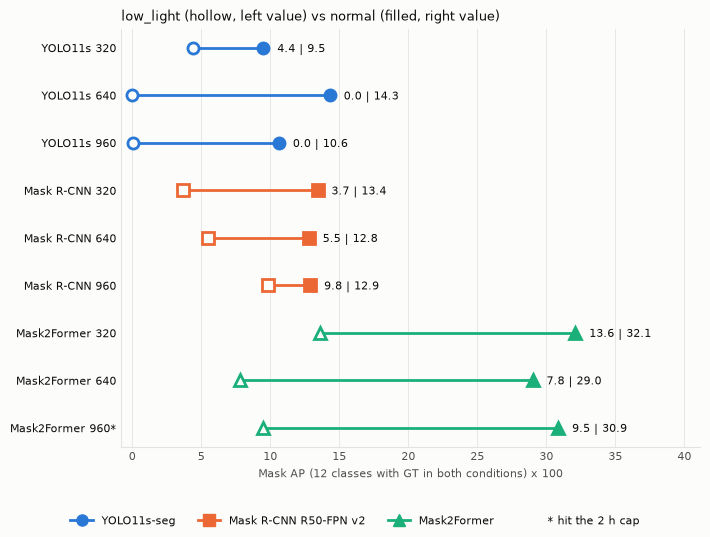

In [10]:
rp.plot_conditions(tables['conditions'], main, save_to=SAVE and out / 'phone_conditions.png');

In [11]:
cond = tables['conditions'].copy()
cond[['AP', 'AP_common', 'AP50_common']] *= 100
display(cond.drop_duplicates('condition')[
    ['condition', 'n_images', 'n_gt', 'n_categories', 'n_common_classes', 'n_gt_common']])
cond.pivot(index='run_id', columns='condition', values=['AP_common', 'AP']).loc[
    main['run_id'].unique()]

,condition,n_images,n_gt,n_categories,n_common_classes,n_gt_common
0,normal,28,123,17,12,101
1,low_light,12,43,12,12,43


AP_common               AP       
condition            low_light normal low_light normal
run_id                                                
yolo_s320_seed42           4.4    9.5       4.4    6.7
yolo_s640_seed42           0.0   14.3       0.0   10.1
yolo_s960_seed42           0.0   10.6       0.0    7.5
maskrcnn_s320_seed42       3.7   13.4       3.7    9.8
maskrcnn_s640_seed42       5.5   12.8       5.5   10.7
maskrcnn_s960_seed42       9.8   12.9       9.8    9.7
m2f_s320_seed42           13.6   32.1      13.6   30.1
m2f_s640_seed42            7.8   29.0       7.8   25.1
m2f_s960_seed42            9.5   30.9       9.5   29.3

## Per-class AP

The common classes, ordered by their instance count on the phone set. Classes with few instances (see the brackets) give noisy values.

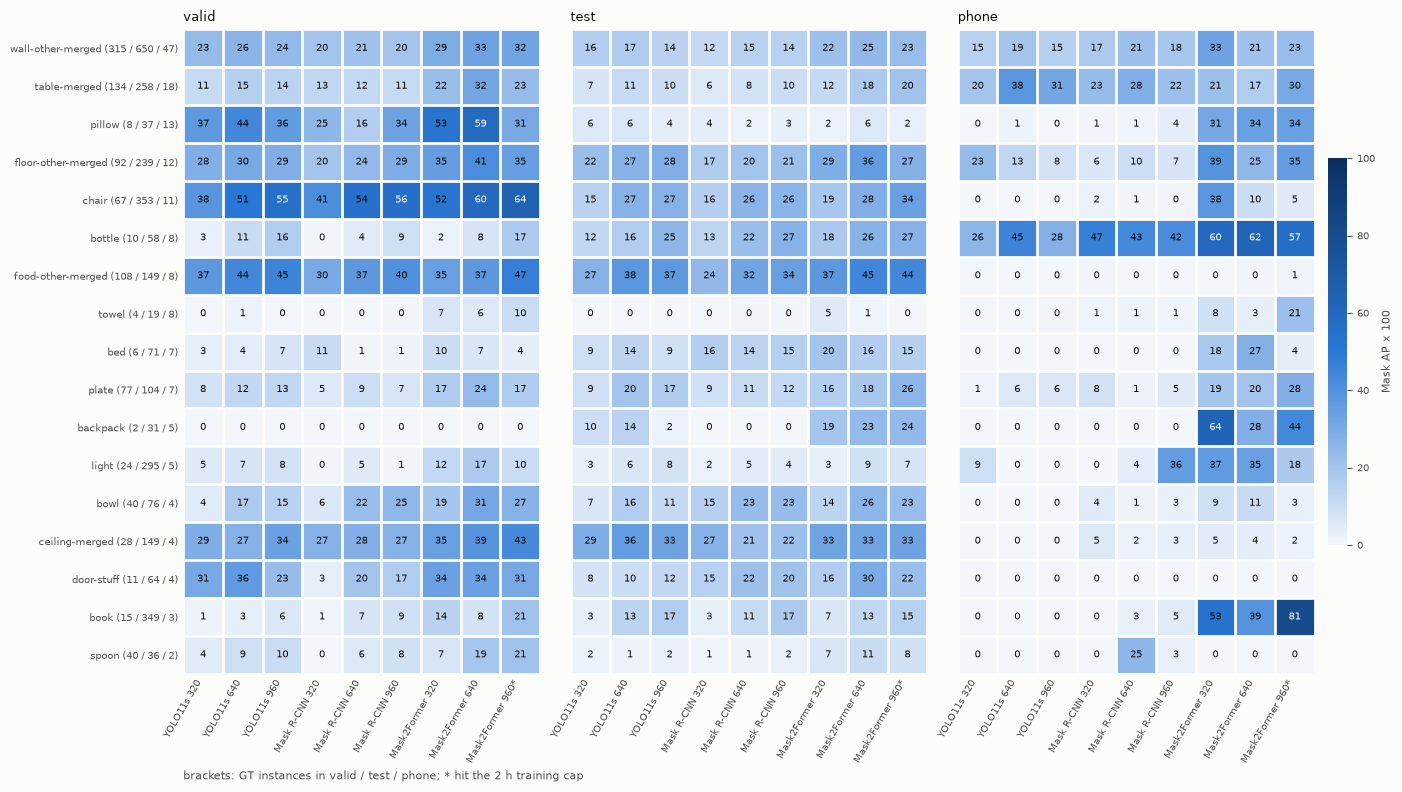

In [12]:
rp.plot_per_class_heatmap(tables['per_class_ap'], common,
                          SAVE and out / 'per_class_heatmap.png', rp.capped_runs(main));

## Things and stuff, classes in and absent from train

Mask AP per category group. A missing value means that the set has no GT for the group.

In [13]:
groups = tables['category_groups'].assign(AP=lambda d: 100 * d['AP'])
groups.pivot(index='run_id', columns=['eval_set', 'group'], values='AP').loc[
    main['run_id'].unique()]

eval_set              valid                                  test                                 phone                               
group                things stuff in_train absent_in_train things stuff in_train absent_in_train things stuff in_train absent_in_train
run_id                                                                                                                                
yolo_s320_seed42       19.7  17.8     19.3             0.0    7.0   7.4      8.2             0.0    3.3   7.4      5.5             NaN
yolo_s640_seed42       28.4  21.3     26.1             0.0   11.3   9.9     12.4             0.0    6.4   7.9      7.2             NaN
yolo_s960_seed42       27.0  19.7     24.5             0.0   11.5   8.7     12.0             0.0    4.2   6.2      5.3             NaN
maskrcnn_s320_seed42   13.9  12.6     13.6             0.0    6.7   6.3      7.5             0.0    7.6   6.0      6.8             NaN
maskrcnn_s640_seed42   17.9  14.9     17.0             0.0   10.0   7.4     10.4             0.0    9.3   7.6      8.4             NaN
maskrcnn_s960_seed42   20.1  14.4     18.2             0.0   10.5   7.8     10.9             0.0    7.1  10.1      8.7             NaN
m2f_s320_seed42        26.0  25.3     26.2             0.0   14.0  10.7     14.6             0.3   32.5  19.3     25.5             NaN
m2f_s640_seed42        32.3  27.6     30.9             0.0   19.8  14.5     20.4             0.3   24.7  15.4     19.8             NaN
m2f_s960_seed42        33.6  26.0     31.1             0.0   17.2  13.5     18.2             0.0   27.5  18.3     22.6             NaN